# Tasks - Lab 5


### Task 3.1: Handling Incomplete Data & Elastic Moduli in Binary Nitrides

✓ Retrieved 917 SummaryDoc documents in 0.9s

Total binary nitride documents retrieved: 917
Total records           : 917
Missing K_VRH entries   : 596 (65.0%)
Cleaned dataset records : 320
--- Top 5 Incompressible Binary Nitrides (Highest K_VRH) ---


,material_id,formula,crystal_system,density,k_vrh
299,mp-2852,C3N4,Cubic,3.776864,441.727
317,mp-1642,Ta5N6,Hexagonal,13.479930,418.890
296,mp-1985,C3N4,Hexagonal,3.501430,408.257
237,mp-1009818,CN2,Tetragonal,3.639646,397.571
21,mp-999266,ReN,Hexagonal,16.591293,392.349


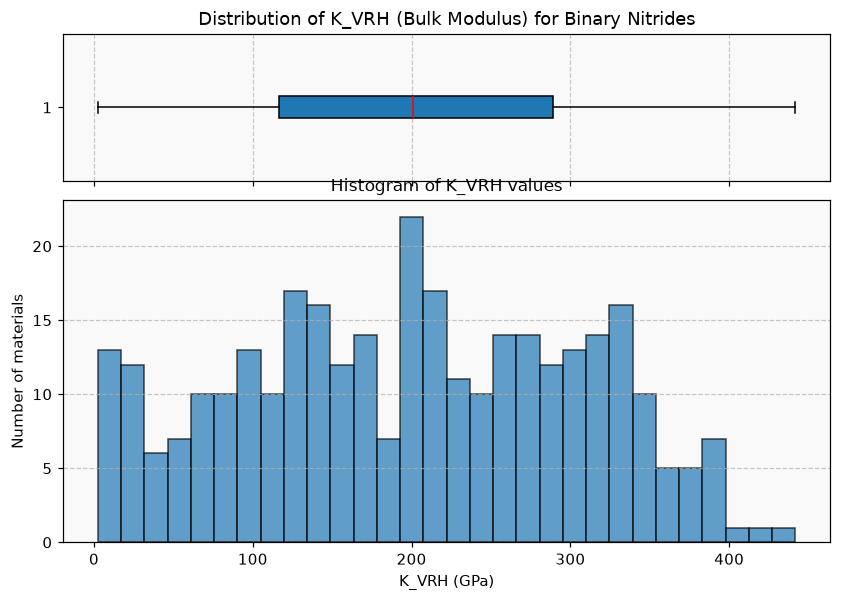

In [34]:
import os
import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from mp_api.client import MPRester

target_fields = ["material_id", "formula_pretty", "bulk_modulus", "density", "symmetry"]
load_dotenv()
API_KEY = os.getenv("MP_API_KEY")
with MPRester(API_KEY) as mpr:
    docs_nitrides = mpr.materials.summary.search(
        elements=["N"], num_elements=2, fields=target_fields
    )

print(f"Total binary nitride documents retrieved: {len(docs_nitrides)}")

records = []
for doc in docs_nitrides:
    bm_data = doc.bulk_modulus
    k_vrh = bm_data.get("vrh") if bm_data else None
    crystal_system = doc.symmetry.crystal_system if doc.symmetry else None
    records.append(
        {
            "material_id": doc.material_id,
            "formula": doc.formula_pretty,
            "crystal_system": crystal_system,
            "density": doc.density,
            "k_vrh": k_vrh,
        }
    )

df_nitrides_all = pd.DataFrame(records)
missing_count = df_nitrides_all["k_vrh"].isna().sum()
pct_missing = missing_count / len(df_nitrides_all) * 100
print(f"Total records           : {len(df_nitrides_all)}")
print(f"Missing K_VRH entries   : {missing_count} ({pct_missing:.1f}%)")

df_nitrides_clean = (
    df_nitrides_all[df_nitrides_all["k_vrh"].between(0, 1_000)]
    .dropna(subset="k_vrh")
    .reset_index(drop=True)
)
print(f"Cleaned dataset records : {len(df_nitrides_clean)}")

top5_nitrides = df_nitrides_clean.sort_values(by="k_vrh", ascending=False)[:5]
print("--- Top 5 Incompressible Binary Nitrides (Highest K_VRH) ---")
display(top5_nitrides[["material_id", "formula", "crystal_system", "density", "k_vrh"]])

fig, (ax_box, ax_hist) = plt.subplots(
    2,
    1,
    figsize=(9, 6),
    dpi=110,
    sharex=True,
    gridspec_kw={"height_ratios": [0.3, 0.7], "hspace": 0.08},
)
k_vrh = df_nitrides_clean["k_vrh"]

ax_box.set_title(
    "Distribution of K_VRH (Bulk Modulus) for Binary Nitrides", fontsize=12
)
ax_box.set_yticks([])
ax_box.set_facecolor("#f9f9f9")
ax_box.grid(axis="x", linestyle="--", alpha=0.7)
ax_box.boxplot(
    k_vrh,
    orientation="horizontal",
    patch_artist=True,
    boxprops=dict(facecolor="#1f77b4", color="black"),
    medianprops=dict(color="red"),
)

ax_hist.hist(k_vrh, bins=30, color="#1f77b4", alpha=0.7, edgecolor="black")
ax_hist.set_title("Histogram of K_VRH values", fontsize=11)
ax_hist.set_xlabel("K_VRH (GPa)", fontsize=10)
ax_hist.set_ylabel("Number of materials", fontsize=10)
ax_hist.grid(axis="y", linestyle="--", alpha=0.7)
ax_hist.set_facecolor("#f9f9f9")

plt.show()

### Task 3.2: Bimodal Distribution Splitting & Target Normalization in Band Gaps

✓ Retrieved 1,606 SummaryDoc documents in 1.2s

Total raw documents retrieved: 1606
Deduplicated dataset size: 1599
Conductors (Metals, Eg == 0)      : 458 (28.6%)
Semiconductors/Insulators (Eg > 0): 1141 (71.4%)
Optimal Box-Cox parameter (λ): 0.506
Raw Eg Skewness              : 1.333
Box-Cox Transformed Skewness : 0.074


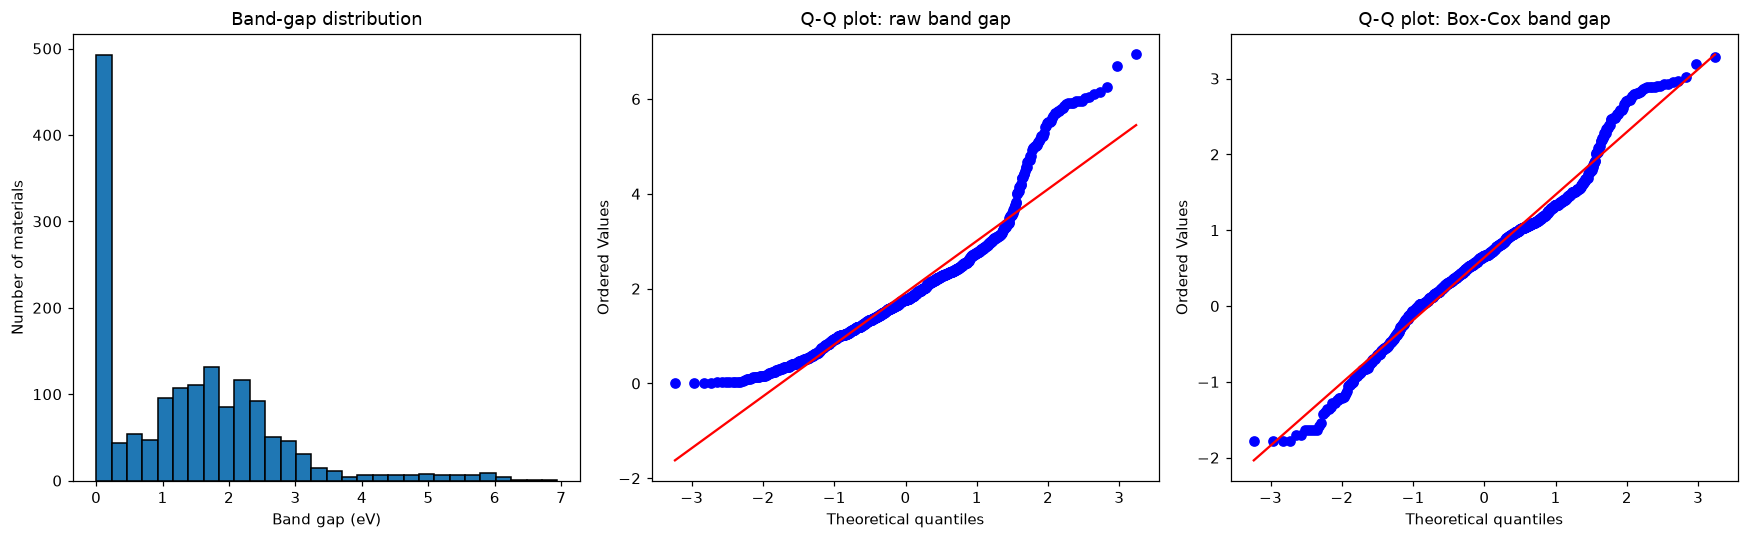

In [35]:
# ==============================================================================
# TASK 3.2: Bimodal Distribution Splitting & Target Normalization in Band Gaps
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mp_api.client import MPRester
from scipy import stats

# 1. Define target fields for field projection
target_fields = ["material_id", "formula_pretty", "band_gap", "is_metal"]

# 2. Query summary endpoint for stable binary and ternary sulfur compounds
with MPRester(API_KEY) as mpr:
    docs_chalcogenides = mpr.materials.summary.search(
        elements=["S"], num_elements=(2, 3), is_stable=True, fields=target_fields
    )

print(f"Total raw documents retrieved: {len(docs_chalcogenides)}")

# 3. Serialize to DataFrame and deduplicate formulas
records = []
for doc in docs_chalcogenides:
    records.append(
        {
            "material_id": doc.material_id,
            "formula": doc.formula_pretty,
            "band_gap": round(doc.band_gap, 2) if doc.band_gap is not None else None,
            "is_metal": doc.is_metal,
        }
    )

df_chalc = pd.DataFrame(records)
df_chalc_clean = (
    df_chalc.dropna(subset=["band_gap"])
    .drop_duplicates(subset="formula", keep="first")
    .reset_index(drop=True)
)
print(f"Deduplicated dataset size: {len(df_chalc_clean)}")

# 4. Split into conductors and semiconductors using row-wise boolean masks
df_metals = df_chalc_clean[df_chalc_clean["band_gap"] == 0.0].copy()
df_semiconductors = df_chalc_clean[df_chalc_clean["band_gap"] > 0.0].copy()

pct_metals = len(df_metals) / len(df_chalc_clean) * 100
print(f"Conductors (Metals, Eg == 0)      : {len(df_metals)} ({pct_metals:.1f}%)")
print(
    f"Semiconductors/Insulators (Eg > 0): "
    f"{len(df_semiconductors)} ({100 - pct_metals:.1f}%)"
)

# 5. Apply transformations on the semiconductor subset
df_semiconductors["band_gap_log"] = np.log1p(df_semiconductors["band_gap"])
bg_boxcox, opt_lambda = stats.boxcox(df_semiconductors["band_gap"])
df_semiconductors["band_gap_boxcox"] = bg_boxcox

print(f"Optimal Box-Cox parameter (λ): {opt_lambda:.3f}")
print(f"Raw Eg Skewness              : {stats.skew(df_semiconductors['band_gap']):.3f}")
print(
    f"Box-Cox Transformed Skewness : "
    f"{stats.skew(df_semiconductors['band_gap_boxcox']):.3f}"
)

# 6. Multi-panel diagnostic visualization in pure matplotlib
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=110)

axes[0].hist(df_chalc_clean["band_gap"], bins=30, color="#1f77b4", edgecolor="black")
axes[0].set_title("Band-gap distribution")
axes[0].set_xlabel("Band gap (eV)")
axes[0].set_ylabel("Number of materials")

stats.probplot(df_semiconductors["band_gap"], dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot: raw band gap")

stats.probplot(df_semiconductors["band_gap_boxcox"], dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot: Box-Cox band gap")

plt.tight_layout()
plt.show()

In [36]:
def check_applicability(formula, ad_domain):
    composition = Composition(formula)
    fractions = {
        element.symbol: composition.get_atomic_fraction(element)
        for element in composition.elements
    }
    violations = []

    for element, fraction in fractions.items():
        if element not in ad_domain.columns:
            violations.append(f"{element} is not present in the training domain")
            continue

        minimum = ad_domain.loc["min", element]
        maximum = ad_domain.loc["max", element]
        if fraction < minimum or fraction > maximum:
            violations.append(
                f"{element} fraction {fraction:.3f} is outside "
                f"[{minimum:.3f}, {maximum:.3f}]"
            )

    is_in_domain = not violations
    return {
        "formula": formula,
        "is_in_domain": is_in_domain,
        "status": "IN-DOMAIN" if is_in_domain else "OUT-OF-DOMAIN",
        "violations": violations,
    }


### Task 3.3: Constructing & Auditing an Applicability Domain for Binary Sulfides

In [37]:
# ==============================================================================
# TASK 3.3: STUDENT STARTER CODE
# ==============================================================================
import pandas as pd
from mp_api.client import MPRester
from pymatgen.core import Composition

# 1. Define target fields for field projection
# Include: material_id, formula_pretty, energy_above_hull
target_fields = ["material_id", "formula_pretty", "energy_above_hull"]

# 2. Query summary endpoint for stable binary sulfides
with MPRester(API_KEY) as mpr:
    # : Query summary endpoint with elements=["S"], num_elements=2,
    #       is_stable=True, fields=target_fields
    docs_sulfides = mpr.materials.summary.search(
        elements=["S"], num_elements=2, is_stable=True, fields=target_fields
    )

print(f"Total raw binary sulfide records: {len(docs_sulfides)}")

# 3. Serialize and deduplicate by ground-state stability
records = []
for doc in docs_sulfides:
    records.append(
        {
            "material_id": doc.material_id,
            "formula": doc.formula_pretty,
            "energy_above_hull": doc.energy_above_hull,
        }
    )

df_sulfides = pd.DataFrame(records)  # TODO: pd.DataFrame(records)

# : Sort by 'energy_above_hull' ascending and deduplicate by 'formula' (keep='first')
df_sulfides_clean = (
    df_sulfides.sort_values(by="energy_above_hull", ascending=True)
    .drop_duplicates(subset="formula", keep="first")
    .reset_index(drop=True)
)

print(f"Deduplicated binary sulfides: {len(df_sulfides_clean)}")

# 4. Construct the Periodic Table Feature Matrix (Atomic Fractions)
# : Convert 'formula' column to Composition objects
compositions = df_sulfides_clean["formula"].apply(Composition)

# TODO: Extract sorted list of unique element symbols present in compositions
unique_elements = sorted({el.symbol for comp in compositions for el in comp.elements})
print(f"Unique elements in binary sulfides training corpus: {len(unique_elements)}")

# : Build list of dictionaries mapping element symbol to atomic fraction
ad_rows = []
for comp in compositions:
    row_dict = {
        el: comp.get_atomic_fraction(el) for el in unique_elements
    }  # {el: comp.get_atomic_fraction(el) for el in unique_elements}
    ad_rows.append(row_dict)

df_ad_sulfides = pd.DataFrame(ad_rows).fillna(
    0.0
)  # : pd.DataFrame(ad_rows).fillna(0.0)

# 5. Extract bounding box (min and max atomic fraction per element)
ad_domain_sulfides = df_ad_sulfides.describe().loc[
    ["min", "max"]
]  # : df_ad_sulfides.describe().loc[['min', 'max']]

print("\n--- Applicability Domain: Sulfur and Transition Metal Limits ---")
sample_elements = [
    el for el in ["S", "Fe", "Cu", "Mo", "Ti"] if el in ad_domain_sulfides.columns
]
display(ad_domain_sulfides[sample_elements])

# 6. Audit candidate formulas using check_applicability()
test_candidates = ["FeS2", "FeS", "H2S", "Au3S", "Cu2FeSnS4"]

print("\n--- Candidate Applicability Domain Audit ---")
for formula in test_candidates:
    # : Call check_applicability(formula, ad_domain_sulfides) and display verdict
    report = check_applicability(formula, ad_domain_sulfides)
    status_icon = "✓" if report["is_in_domain"] else "✗"
    print(
        f"{status_icon} Formula: {report['formula']:<12} | Status: {report['status']}"
    )
    for violation in report["violations"]:
        print(f"    └── Reason: {violation}")

✓ Retrieved 204 SummaryDoc documents in 0.8s

Total raw binary sulfide records: 204
Deduplicated binary sulfides: 204
Unique elements in binary sulfides training corpus: 79

--- Applicability Domain: Sulfur and Transition Metal Limits ---


,S,Fe,Cu,Mo,Ti
min,0.142857,0.000000,0.000000,0.000000,0.000000
max,0.800000,0.333333,0.636364,0.333333,0.666667



--- Candidate Applicability Domain Audit ---
✓ Formula: FeS2         | Status: IN-DOMAIN
✗ Formula: FeS          | Status: OUT-OF-DOMAIN
    └── Reason: Fe fraction 0.500 is outside [0.000, 0.333]
✓ Formula: H2S          | Status: IN-DOMAIN
✗ Formula: Au3S         | Status: OUT-OF-DOMAIN
    └── Reason: Au fraction 0.750 is outside [0.000, 0.667]
✓ Formula: Cu2FeSnS4    | Status: IN-DOMAIN


### Task 3.4 (*): Multi-Scale Featurization & Testing the "Heaviest Element" Hypothesis

In [ ]:
# ==============================================================================
# TASK 3.4 (*): Multi-Scale Featurization & Testing the "Heaviest Element" Hypothesis
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mp_api.client import MPRester
from pymatgen.core import Composition
from scipy import stats

# 1. Define target fields for projection
target_fields = ["material_id", "formula_pretty", "density"]

# 2. Query summary endpoint for stable ternary compounds
with MPRester(API_KEY) as mpr:
    docs_ternary = mpr.materials.summary.search(
        num_elements=3, is_stable=True, fields=target_fields
    )

print(f"Total raw ternary documents retrieved: {len(docs_ternary)}")

# 3. Serialize to a DataFrame and deduplicate formulas
records = []
for doc in docs_ternary:
    records.append(
        {
            "material_id": doc.material_id,
            "formula": doc.formula_pretty,
            "density": doc.density,
        }
    )

df_ternary = pd.DataFrame(records)
df_clean = (
    df_ternary.dropna(subset=["density"])
    .drop_duplicates(subset="formula", keep="first")
    .reset_index(drop=True)
)
print(f"Cleaned unique ternary compounds: {len(df_clean)}")

# 4. Extract maximum and composition-weighted mean atomic masses
def extract_mass_metrics(formula_str: str) -> tuple[float, float]:
    """Return maximum and weighted mean constituent atomic masses in amu."""
    comp = Composition(formula_str)
    max_m = max(float(element.atomic_mass) for element in comp.elements)
    mean_m = sum(
        float(element.atomic_mass) * comp.get_atomic_fraction(element)
        for element in comp.elements
    )
    return max_m, mean_m

mass_metrics = df_clean["formula"].apply(extract_mass_metrics)
df_clean[["max_atomic_mass", "mean_atomic_mass"]] = pd.DataFrame(
    mass_metrics.tolist(), index=df_clean.index
)

# 5. Compute Pearson correlation coefficients
r_max, p_max = stats.pearsonr(df_clean["density"], df_clean["max_atomic_mass"])
r_mean, p_mean = stats.pearsonr(df_clean["density"], df_clean["mean_atomic_mass"])
print(f"Density vs. maximum atomic mass: r = {r_max:.3f}, p = {p_max:.3e}")
print(f"Density vs. mean atomic mass   : r = {r_mean:.3f}, p = {p_mean:.3e}")

# 6. Sequential single-figure visualizations
def plot_density_relationship(x_column, x_label, title, correlation):
    x = df_clean[x_column].to_numpy()
    y = df_clean["density"].to_numpy()
    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 200)

    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, alpha=0.55, s=22, edgecolors="none", label="Ternary compounds")
    plt.plot(
        x_line,
        slope * x_line + intercept,
        color="crimson",
        linewidth=2,
        label=f"Linear fit (r = {correlation:.3f})",
    )
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel("Density (g/cm³)")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()

plot_density_relationship(
    "max_atomic_mass",
    "Maximum atomic mass (amu)",
    "Density vs. Maximum Atomic Mass",
    r_max,
)
plot_density_relationship(
    "mean_atomic_mass",
    "Mean atomic mass (amu)",
    "Density vs. Mean Atomic Mass",
    r_mean,
)
